# Ноутбук 4 (Трек D): Финальный мета-синтез (`Caruana GES`, 5-семейный ансамбль), EM-адаптация Саеренса, стат. тесты ДеЛонга / бутстрепа и клинический Error Analysis

**Финальный зависимый каскад исследования (все решения отбора — строго на `Train OOF n=82`):**
1. **Exp D1 (Мета-сборка 5 ортогональных семейств и вложенная OOF-калибровка):**
   - Аудит всех 23 моделей Треков A и B + корреляция ошибок между семействами (`Linear`, `Trees`, `TFM`, `Graph/G2T`, `Deep Tabular PLE`).
   - Вложенная 5×5 CV логит-калибровка для снятия оптимизма ранней остановки DL-моделей.
   - Сравнение `Naive Caruana GES`, `Calibrated Regularized GES`, `Family-5 Balanced Logits` и `Family-5 Rank Blend`.
2. **Exp D2 (Слепой экзамен на $N=344$, `Saerens EM` и статистическая значимость):**
   - Оценка на `Internal (83)`, `Ext1 (127)`, `Ext2 (134)`, `Pooled_Ext (261)` и `All_Holdout (344)` до и после слепой EM-адаптации Саеренса ($\alpha_{\text{reg}}=2.0$).
   - Парный тест ДеЛонга + 1000-кратный стратифицированный бутстреп (95% CI для AUROC и AUPR, `ECE`, `Brier`, точность $\hat{\pi}_{\text{EM}}^*$).
3. **Exp D3 (Клинический Error Analysis и сводный отчёт по Контурам А + Б):**
   - Разбор ложноположительных/ложноотрицательных пациенток (вклад иммунной оси `B2M/SPI`, гетероскедастической надёжности ИФА $W_i$ и квантильного сдвига).
   - Финальная сводка с полнопротеомным `P-NET` Чунцина (Трек C).

In [1]:
import os
import sys
import json
import zipfile
import shutil
import warnings
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.special import expit, logit
from scipy.optimize import minimize

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
})

def unpack_archive_if_needed(zip_names: List[str], check_file: Path, target_dir: Path) -> Path:
    if check_file.exists():
        return target_dir
    for zname in zip_names:
        for base in [Path("."), Path("/content"), Path("/content/drive/MyDrive")]:
            zp = base / zname
            if zp.exists():
                target_dir.mkdir(parents=True, exist_ok=True)
                print(f"[UNZIP] {zp} -> {target_dir.resolve()}")
                with zipfile.ZipFile(zp, "r") as zf:
                    zf.extractall(target_dir)
                if check_file.exists():
                    return target_dir
                for found in target_dir.rglob(check_file.name):
                    return found.parents[len(check_file.relative_to(target_dir).parts) - 1]
    raise FileNotFoundError(f"Не найден {check_file} или архив из {zip_names}.")

DATA_DIR = unpack_archive_if_needed(["data.zip", "sptb_data.zip"], Path("./data/cohort_a_426_enriched.parquet"), Path("./data"))
ARTIFACTS_DIR = unpack_archive_if_needed(["artifacts.zip"], Path("./artifacts/splits/Train_5x5_CV.json"), Path("./artifacts"))

SPLITS_DIR = ARTIFACTS_DIR / "splits"
TRACK_A_DIR = ARTIFACTS_DIR / "track_a"
TRACK_B_DIR = ARTIFACTS_DIR / "track_b"
TRACK_C_DIR = ARTIFACTS_DIR / "track_c"
TRACK_D_DIR = ARTIFACTS_DIR / "track_d"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
for d in [TRACK_D_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

cohort_a = pd.read_parquet(DATA_DIR / "cohort_a_426_enriched.parquet")
dataset_features = pd.read_parquet(DATA_DIR / "dataset_features.parquet").set_index("Sample ID")

with open(SPLITS_DIR / "Train_5x5_CV.json", "r", encoding="utf-8") as f:
    train_5x5_splits = json.load(f)

train_mask = (cohort_a["Dataset"] == "Train").values
holdout_mask = ~train_mask
train_ids = cohort_a.index[train_mask]
holdout_ids = cohort_a.index[holdout_mask]

y_train_82 = cohort_a["Target"].values[train_mask].astype(int)
y_holdout = cohort_a["Target"].values[holdout_mask].astype(int)
ds_holdout = cohort_a["Dataset"].values[holdout_mask]

m_int = ds_holdout == "Internal validation"
m_ext1 = ds_holdout == "External validation1"
m_ext2 = ds_holdout == "External validation2"
m_ext_pool = m_ext1 | m_ext2
m_all_hold = np.ones_like(m_int, dtype=bool)
PI_TRAIN = float(np.mean(y_train_82))

print(f"[OK] Загружены данные Cohort A (Train={len(y_train_82)}, Holdout={len(y_holdout)}) и все артефакты Треков A/B/C.")

[UNZIP] data.zip -> /content/data
[UNZIP] artifacts.zip -> /content/artifacts
[OK] Загружены данные Cohort A (Train=82, Holdout=344) и все артефакты Треков A/B/C.


In [2]:
def estimate_prior_saerens_em(probs: np.ndarray, pi_train: float, alpha_reg: float = 2.0, max_iter: int = 500, tol: float = 1e-6) -> float:
    p = np.clip(np.asarray(probs, dtype=float), 1e-6, 1.0 - 1e-6)
    n_c = len(p)
    pi_c = float(pi_train)
    for _ in range(max_iter):
        r1 = pi_c / pi_train
        r0 = (1.0 - pi_c) / (1.0 - pi_train)
        q = (p * r1) / (p * r1 + (1.0 - p) * r0 + 1e-12)
        pi_next = float(np.clip((np.sum(q) + alpha_reg * pi_train) / (n_c + alpha_reg), 0.03, 0.85))
        if abs(pi_next - pi_c) < tol:
            pi_c = pi_next
            break
        pi_c = pi_next
    return pi_c

def adjust_probs_saerens(probs: np.ndarray, pi_train: float, alpha_reg: float = 2.0) -> Tuple[np.ndarray, float]:
    p = np.clip(np.asarray(probs, dtype=float), 1e-6, 1.0 - 1e-6)
    pi_est = estimate_prior_saerens_em(p, pi_train=pi_train, alpha_reg=alpha_reg)
    z = logit(p)
    delta = np.log(pi_est / (1.0 - pi_est)) - np.log(pi_train / (1.0 - pi_train))
    return expit(z + delta), pi_est

def compute_ece(y_true: np.ndarray, probs: np.ndarray, n_bins: int = 10) -> float:
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n = len(y_true)
    for i in range(n_bins):
        if i == n_bins - 1:
            in_b = (probs >= bins[i]) & (probs <= bins[i + 1])
        else:
            in_b = (probs >= bins[i]) & (probs < bins[i + 1])
        cnt = int(np.sum(in_b))
        if cnt > 0:
            acc = float(np.mean(y_true[in_b]))
            conf = float(np.mean(probs[in_b]))
            ece += (cnt / n) * abs(acc - conf)
    return float(ece)

def compute_full_metrics(y_true: np.ndarray, probs: np.ndarray, threshold: float = 0.3500) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=int)
    probs = np.clip(np.asarray(probs, dtype=float), 1e-7, 1.0 - 1e-7)
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {
        "AUROC": float(roc_auc_score(y_true, probs)),
        "AUPR": float(average_precision_score(y_true, probs)),
        "F1": float(f1_score(y_true, preds, zero_division=0)),
        "Sens": float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0,
        "Spec": float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0,
        "PPV": float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0,
        "NPV": float(tn / (tn + fn)) if (tn + fn) > 0 else 0.0,
        "Brier": float(brier_score_loss(y_true, probs)),
        "LogLoss": float(log_loss(y_true, probs)),
        "ECE": compute_ece(y_true, probs, n_bins=10),
    }

def delong_roc_test(y_true: np.ndarray, probs_a: np.ndarray, probs_b: np.ndarray) -> Tuple[float, float]:
    y_true = np.asarray(y_true, dtype=int)
    pos, neg = y_true == 1, y_true == 0
    m, n = int(np.sum(pos)), int(np.sum(neg))
    if m < 2 or n < 2:
        return 0.0, 1.0
    def _comp(scores):
        diff = scores[pos, None] - scores[None, neg]
        psi = np.where(diff > 0, 1.0, np.where(diff == 0, 0.5, 0.0))
        v10, v01 = np.mean(psi, axis=1), np.mean(psi, axis=0)
        return float(np.mean(v10)), v10, v01
    auc_a, v10_a, v01_a = _comp(np.asarray(probs_a, dtype=float))
    auc_b, v10_b, v01_b = _comp(np.asarray(probs_b, dtype=float))
    s = np.cov(np.vstack([v10_a, v10_b]), ddof=1) / m + np.cov(np.vstack([v01_a, v01_b]), ddof=1) / n
    var_diff = s[0, 0] + s[1, 1] - 2.0 * s[0, 1]
    if var_diff <= 1e-12:
        return 0.0, 1.0
    z_stat = (auc_a - auc_b) / np.sqrt(var_diff)
    return float(z_stat), float(2.0 * stats.norm.sf(abs(z_stat)))

def paired_stratified_bootstrap(y_true: np.ndarray, probs_a: np.ndarray, probs_b: np.ndarray, n_boot: int = 1000) -> Dict[str, Any]:
    rng = np.random.default_rng(SEED)
    pos_idx = np.where(y_true == 1)[0]
    neg_idx = np.where(y_true == 0)[0]
    aucs_a, auprs_a, d_aucs, d_auprs = [], [], [], []
    for _ in range(n_boot):
        bp = rng.choice(pos_idx, size=len(pos_idx), replace=True)
        bn = rng.choice(neg_idx, size=len(neg_idx), replace=True)
        idx = np.concatenate([bp, bn])
        yb = y_true[idx]
        pa = probs_a[idx]
        pb = probs_b[idx]
        aa, ab = roc_auc_score(yb, pa), roc_auc_score(yb, pb)
        pa_pr, pb_pr = average_precision_score(yb, pa), average_precision_score(yb, pb)
        aucs_a.append(aa)
        auprs_a.append(pa_pr)
        d_aucs.append(aa - ab)
        d_auprs.append(pa_pr - pb_pr)
    d_aucs = np.array(d_aucs)
    d_auprs = np.array(d_auprs)
    p_delta_aupr = float(2.0 * min(np.mean(d_auprs <= 0), np.mean(d_auprs >= 0)))
    return {
        "AUROC_CI95": (float(np.percentile(aucs_a, 2.5)), float(np.percentile(aucs_a, 97.5))),
        "AUPR_CI95": (float(np.percentile(auprs_a, 2.5)), float(np.percentile(auprs_a, 97.5))),
        "Delta_AUROC_mean": float(np.mean(d_aucs)),
        "Delta_AUPR_mean": float(np.mean(d_auprs)),
        "p_boot_AUPR": min(p_delta_aupr, 1.0),
    }

print("[OK] Утилиты статистики (Saerens EM, ECE, DeLong, 1000-Bootstrap) готовы.")

[OK] Утилиты статистики (Saerens EM, ECE, DeLong, 1000-Bootstrap) готовы.


In [7]:
FAMILY_MAP = {
    "Baseline_LogReg_5Markers": "1_Linear_LUPI",
    "TrackA_Best_ElasticNet": "1_Linear_LUPI",
    "P5_MS_Top4_NoAMBP_LogReg": "1_Linear_LUPI",
    "SinglePatient_ShiftFree_LogReg": "Excluded_ShiftBroken",

    "TrackA_Best_ExtraTrees_d4": "2_Randomized_Trees",
    "P5_MS_Top4_NoAMBP_ExtraTrees": "2_Randomized_Trees",
    "TrackA_Best_CatBoost_Ordered": "2_Randomized_Trees",
    "Bridge_4Markers_NoTIMP1_CatBoost": "Excluded_BridgeOnly",

    "TabPFN_V1_Core5": "3_InContext_TFM",
    "TabPFN_V2_NoAMBP4": "3_InContext_TFM",
    "TabPFN_TAG_Equal": "3_InContext_TFM",
    "TabPFN_TAG_ES": "3_InContext_TFM",
    "TabICLv2_V1_Core5": "3_InContext_TFM",
    "TabICLv2_M10_Triples": "3_InContext_TFM",
    "TabICLv2_TAG_Equal": "3_InContext_TFM",

    "G2T_FM_TabPFN": "4_Graph_G2T_GNN",
    "G2T_FM_TabICLv2": "4_Graph_G2T_GNN",
    "InductiveMVGAT": "4_Graph_G2T_GNN",
    "G2T_FM_plus_ShiftedLP": "Excluded_ClipArtifact",

    "TabM_mini_PLE5_Core5": "5_Deep_Tabular",
    "TabM_mini_PLE5_NoAMBP4": "5_Deep_Tabular",
    "TabR_PLRlite_Core5": "5_Deep_Tabular",
    "T2GFormer_Compact_Core5": "5_Deep_Tabular",
    "TabM_mini_Periodic_Core5": "Excluded_PhaseWrap",
}

model_store = {}
for track_dir in [TRACK_A_DIR, TRACK_B_DIR]:
    for oof_path in sorted(track_dir.glob("oof_*.parquet")):
        m_name = oof_path.stem[4:]
        test_path = track_dir / f"test_{m_name}.parquet"
        if not test_path.exists() or m_name not in FAMILY_MAP:
            continue
        df_oof = pd.read_parquet(oof_path)
        df_test = pd.read_parquet(test_path)
        assert (df_oof.index == train_ids).all(), f"Индекс OOF не совпадает у {m_name}"
        assert (df_test.index == holdout_ids).all(), f"Индекс Test не совпадает у {m_name}"

        oof_l = df_oof["oof_logit"].values.astype(float)
        test_l = df_test["test_logit_bagged"].values.astype(float)
        model_store[m_name] = {
            "name": m_name,
            "family": FAMILY_MAP[m_name],
            "oof_logit": oof_l,
            "oof_prob": expit(oof_l),
            "test_logit": test_l,
            "test_prob": expit(test_l),
        }

def nested_oof_temp_calibrate(oof_l: np.ndarray, test_l: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    from scipy.optimize import minimize_scalar
    n_tr = len(y_train_82)
    cal_oof_rep = np.zeros((n_tr, 5))
    cal_test_25 = np.zeros((len(test_l), len(train_5x5_splits)))

    for sp in train_5x5_splits:
        s_id, rep = sp["split_id"], sp["repeat"]
        tr_pos = np.array(sp["train_pos"], dtype=int)
        val_pos = np.array(sp["val_pos"], dtype=int)
        res_opt = minimize_scalar(
            lambda T: log_loss(y_train_82[tr_pos], np.clip(expit(oof_l[tr_pos] / T), 1e-7, 1.0 - 1e-7)),
            bounds=(0.5, 3.0),
            method="bounded",
        )
        t_opt = float(res_opt.x)
        cal_oof_rep[val_pos, rep] = oof_l[val_pos] / t_opt
        cal_test_25[:, s_id] = test_l / t_opt

    return np.mean(cal_oof_rep, axis=1), np.mean(cal_test_25, axis=1)

master_rows = []
for m_name, obj in model_store.items():
    cal_oof_l, cal_test_l = nested_oof_temp_calibrate(obj["oof_logit"], obj["test_logit"])
    obj["cal_oof_logit"] = cal_oof_l
    obj["cal_test_logit"] = cal_test_l

    m_oof_raw = compute_full_metrics(y_train_82, obj["oof_prob"])
    m_oof_cal = compute_full_metrics(y_train_82, expit(cal_oof_l))
    m_pool = compute_full_metrics(y_holdout[m_ext_pool], obj["test_prob"][m_ext_pool])
    master_rows.append({
        "Model": m_name,
        "Family": obj["family"],
        "OOF_AUROC": round(m_oof_raw["AUROC"], 4),
        "OOF_AUPR": round(m_oof_raw["AUPR"], 4),
        "OOF_LogLoss_Raw": round(m_oof_raw["LogLoss"], 4),
        "OOF_LogLoss_Cal": round(m_oof_cal["LogLoss"], 4),
        "PooledExt_AUROC": round(m_pool["AUROC"], 4),
        "PooledExt_AUPR": round(m_pool["AUPR"], 4),
    })

df_master = pd.DataFrame(master_rows).sort_values(["Family", "OOF_LogLoss_Cal"])
print("=== МАСТЕР-РЕЕСТР ВСЕХ МОДЕЛЕЙ ТРЕКОВ A И B (ВЛОЖЕННЫЙ TEMPERATURE SCALING) ===")
print(df_master.to_string(index=False))

active_models = [k for k, v in model_store.items() if not v["family"].startswith("Excluded_")]

=== МАСТЕР-РЕЕСТР ВСЕХ МОДЕЛЕЙ ТРЕКОВ A И B (ВЛОЖЕННЫЙ TEMPERATURE SCALING) ===
                           Model                Family  OOF_AUROC  OOF_AUPR  OOF_LogLoss_Raw  OOF_LogLoss_Cal  PooledExt_AUROC  PooledExt_AUPR
        P5_MS_Top4_NoAMBP_LogReg         1_Linear_LUPI     0.9017    0.7547           0.4089           0.4358           0.9107          0.7652
          TrackA_Best_ElasticNet         1_Linear_LUPI     0.9084    0.7782           0.4183           0.4473           0.9100          0.7735
        Baseline_LogReg_5Markers         1_Linear_LUPI     0.9071    0.7729           0.4242           0.4525           0.9097          0.7727
    P5_MS_Top4_NoAMBP_ExtraTrees    2_Randomized_Trees     0.9380    0.8148           0.3498           0.3399           0.9186          0.7424
       TrackA_Best_ExtraTrees_d4    2_Randomized_Trees     0.9340    0.8111           0.3466           0.3461           0.9092          0.7154
    TrackA_Best_CatBoost_Ordered    2_Randomized_Trees     0.9

In [8]:
def run_caruana_ges(
    logit_matrix_oof: np.ndarray,
    model_names: List[str],
    n_iters: int = 25,
    l2_shrink_to_uniform: float = 0.0,
    max_weight_per_family: float = 1.0,
    families: Optional[List[str]] = None,
) -> Dict[str, float]:
    n_models = len(model_names)
    counts = np.zeros(n_models, dtype=float)
    max_cnt_per_fam = max(1, int(np.floor(max_weight_per_family * n_iters)))

    best_single = int(np.argmin([log_loss(y_train_82, expit(logit_matrix_oof[:, j])) for j in range(n_models)]))
    counts[best_single] += 1.0

    for _ in range(1, n_iters):
        cur_sum = logit_matrix_oof @ counts
        cur_n = float(np.sum(counts))
        best_j, best_ll = None, 1e9
        for j in range(n_models):
            if families is not None and max_weight_per_family < 1.0:
                fam_j = families[j]
                fam_cnt = sum(counts[k] for k in range(n_models) if families[k] == fam_j)
                if fam_cnt + 1.0 > max_cnt_per_fam + 1e-6:
                    continue
            cand_logits = (cur_sum + logit_matrix_oof[:, j]) / (cur_n + 1.0)
            ll = log_loss(y_train_82, expit(cand_logits))
            if ll < best_ll:
                best_ll = ll
                best_j = j
        if best_j is not None:
            counts[best_j] += 1.0

    w = counts / np.sum(counts)
    if l2_shrink_to_uniform > 0.0:
        active_idx = np.where(w > 0)[0]
        w_unif = np.zeros_like(w)
        w_unif[active_idx] = 1.0 / len(active_idx)
        w = (1.0 - l2_shrink_to_uniform) * w + l2_shrink_to_uniform * w_unif

    return {m: float(w[i]) for i, m in enumerate(model_names) if w[i] > 1e-6}


mat_oof_raw = np.column_stack([model_store[m]["oof_logit"] for m in active_models])
mat_oof_cal = np.column_stack([model_store[m]["cal_oof_logit"] for m in active_models])
active_fams = [model_store[m]["family"] for m in active_models]

w_naive_ges = run_caruana_ges(mat_oof_raw, active_models, n_iters=25, l2_shrink_to_uniform=0.0, max_weight_per_family=1.0)
w_cal_reg_ges = run_caruana_ges(
    mat_oof_cal, active_models, n_iters=25, l2_shrink_to_uniform=0.25, max_weight_per_family=0.30, families=active_fams
)

family_leaders_oof = {}
for fam_id in sorted(set(active_fams)):
    cands = [m for m in active_models if model_store[m]["family"] == fam_id]
    best_m = min(cands, key=lambda m: log_loss(y_train_82, expit(model_store[m]["cal_oof_logit"])))
    family_leaders_oof[fam_id] = best_m

print("\n[EXP D1] Лучшие представители 5 ортогональных семейств по вложенному OOF LogLoss (n=82):")
for f_k, m_k in family_leaders_oof.items():
    ll_c = log_loss(y_train_82, expit(model_store[m_k]["cal_oof_logit"]))
    auc_c = roc_auc_score(y_train_82, expit(model_store[m_k]["cal_oof_logit"]))
    print(f"  {f_k:22s} -> {m_k:32s} (OOF Cal LogLoss={ll_c:.4f}, AUROC={auc_c:.4f})")

print("\n[Веса Ens1_Naive_Caruana_GES]:", {k: round(v, 3) for k, v in w_naive_ges.items()})
print("[Веса Ens2_Calibrated_GES_L2]:", {k: round(v, 3) for k, v in w_cal_reg_ges.items()})

leader_list = list(family_leaders_oof.values())
w_fam5_equal = {m: 1.0 / len(leader_list) for m in leader_list}

def apply_weights_to_logits(weight_dict: Dict[str, float], use_calibrated: bool = True) -> Tuple[np.ndarray, np.ndarray]:
    key_o = "cal_oof_logit" if use_calibrated else "oof_logit"
    key_t = "cal_test_logit" if use_calibrated else "test_logit"
    oof_out = sum(w * model_store[m][key_o] for m, w in weight_dict.items())
    test_out = sum(w * model_store[m][key_t] for m, w in weight_dict.items())
    return oof_out, test_out

ens1_oof, ens1_test = apply_weights_to_logits(w_naive_ges, use_calibrated=False)
ens2_oof, ens2_test = apply_weights_to_logits(w_cal_reg_ges, use_calibrated=True)
ens3_oof, ens3_test = apply_weights_to_logits(w_fam5_equal, use_calibrated=True)

def calibrated_prob_blend(model_list: List[str]) -> Tuple[np.ndarray, np.ndarray]:
    oof_p = np.mean([expit(model_store[m]["cal_oof_logit"]) for m in model_list], axis=0)
    test_p = np.mean([expit(model_store[m]["cal_test_logit"]) for m in model_list], axis=0)
    return logit(np.clip(oof_p, 1e-6, 1.0 - 1e-6)), logit(np.clip(test_p, 1e-6, 1.0 - 1e-6))

ens4_oof, ens4_test = calibrated_prob_blend(leader_list)

err_df = pd.DataFrame({m: y_train_82 - expit(model_store[m]["cal_oof_logit"]) for m in leader_list})
print("\n=== КОРРЕЛЯЦИЯ ОСТАТОЧНЫХ ОШИБОК НА OOF (n=82) МЕЖДУ 5 СЕМЕЙСТВАМИ ===")
print(err_df.corr().round(3).to_string())


[EXP D1] Лучшие представители 5 ортогональных семейств по вложенному OOF LogLoss (n=82):
  1_Linear_LUPI          -> P5_MS_Top4_NoAMBP_LogReg         (OOF Cal LogLoss=0.4358, AUROC=0.8963)
  2_Randomized_Trees     -> P5_MS_Top4_NoAMBP_ExtraTrees     (OOF Cal LogLoss=0.3399, AUROC=0.9333)
  3_InContext_TFM        -> TabPFN_TAG_ES                    (OOF Cal LogLoss=0.3640, AUROC=0.9098)
  4_Graph_G2T_GNN        -> InductiveMVGAT                   (OOF Cal LogLoss=0.3112, AUROC=0.9428)
  5_Deep_Tabular         -> TabM_mini_PLE5_Core5             (OOF Cal LogLoss=0.2906, AUROC=0.9448)

[Веса Ens1_Naive_Caruana_GES]: {'TabM_mini_PLE5_Core5': 0.68, 'TabR_PLRlite_Core5': 0.32}
[Веса Ens2_Calibrated_GES_L2]: {'P5_MS_Top4_NoAMBP_ExtraTrees': 0.26, 'InductiveMVGAT': 0.26, 'TabM_mini_PLE5_Core5': 0.17, 'TabPFN_TAG_ES': 0.17, 'TabR_PLRlite_Core5': 0.14}

=== КОРРЕЛЯЦИЯ ОСТАТОЧНЫХ ОШИБОК НА OOF (n=82) МЕЖДУ 5 СЕМЕЙСТВАМИ ===
                              P5_MS_Top4_NoAMBP_LogReg  P5_MS_Top4_NoAMB

In [9]:
exam_candidates = {
    "Zhao_Baseline_LogReg_5Markers": (model_store["Baseline_LogReg_5Markers"]["oof_logit"], model_store["Baseline_LogReg_5Markers"]["test_logit"]),
}
for f_k, m_k in family_leaders_oof.items():
    if m_k != "Baseline_LogReg_5Markers":
        exam_candidates[f"Fam_{f_k[:7]}_{m_k}"] = (model_store[m_k]["cal_oof_logit"], model_store[m_k]["cal_test_logit"])

exam_candidates.update({
    "Ens1_Naive_Caruana_GES": (ens1_oof, ens1_test),
    "Ens2_Calibrated_GES_L2": (ens2_oof, ens2_test),
    "Ens3_Family5_Balanced_Logits": (ens3_oof, ens3_test),
    "Ens4_Family5_Rank_Blend": (ens4_oof, ens4_test),
})

base_hold_probs = expit(exam_candidates["Zhao_Baseline_LogReg_5Markers"][1])

eval_slices = [
    ("Internal_Val (n=83, 32.5%)", m_int),
    ("External_Val1 (n=127, 8.7%)", m_ext1),
    ("External_Val2 (n=134, 17.9%)", m_ext2),
    ("Pooled_External (n=261, 13.4%)", m_ext_pool),
    ("All_Holdout (n=344, 18.0%)", m_all_hold),
]

rows_d2 = []
saerens_priors_rows = []
calibrated_probs_store = {}

for cname, (oof_l, test_l) in exam_candidates.items():
    p_hold_raw = expit(test_l)
    p_hold_em = np.zeros_like(p_hold_raw)
    pi_dict = {}
    for ck, cm in [("Internal", m_int), ("Ext1", m_ext1), ("Ext2", m_ext2)]:
        p_adj, pi_est = adjust_probs_saerens(p_hold_raw[cm], pi_train=PI_TRAIN, alpha_reg=2.0)
        p_hold_em[cm] = p_adj
        pi_dict[ck] = pi_est

    calibrated_probs_store[cname] = (expit(oof_l), p_hold_raw, p_hold_em)

    if cname in ("Zhao_Baseline_LogReg_5Markers", "Ens2_Calibrated_GES_L2", "Ens3_Family5_Balanced_Logits"):
        for ck, cm in [("Internal", m_int), ("Ext1", m_ext1), ("Ext2", m_ext2)]:
            saerens_priors_rows.append({
                "Model": cname,
                "Cohort": ck,
                "True_Prevalence": round(float(np.mean(y_holdout[cm])), 4),
                "Saerens_EM_Est": round(pi_dict[ck], 4),
                "Abs_Error": round(abs(pi_dict[ck] - float(np.mean(y_holdout[cm]))), 4),
            })

    for s_name, s_mask in eval_slices:
        y_s = y_holdout[s_mask]
        pr_s = p_hold_raw[s_mask]
        pe_s = p_hold_em[s_mask]
        m_raw = compute_full_metrics(y_s, pr_s)
        m_em = compute_full_metrics(y_s, pe_s)
        _, p_dl = delong_roc_test(y_s, pr_s, base_hold_probs[s_mask])

        boot = paired_stratified_bootstrap(y_s, pr_s, base_hold_probs[s_mask], n_boot=1000) if s_name in ("Pooled_External (n=261, 13.4%)", "All_Holdout (n=344, 18.0%)") else None

        rows_d2.append({
            "Model": cname,
            "Cohort": s_name,
            "AUROC": round(m_raw["AUROC"], 4),
            "AUROC_CI95": f"[{boot['AUROC_CI95'][0]:.3f}-{boot['AUROC_CI95'][1]:.3f}]" if boot else "-",
            "AUPR": round(m_raw["AUPR"], 4),
            "AUPR_CI95": f"[{boot['AUPR_CI95'][0]:.3f}-{boot['AUPR_CI95'][1]:.3f}]" if boot else "-",
            "F1_Raw": round(m_raw["F1"], 4),
            "F1_EM": round(m_em["F1"], 4),
            "Sens_EM": round(m_em["Sens"], 4),
            "Spec_EM": round(m_em["Spec"], 4),
            "PPV_Raw": round(m_raw["PPV"], 4),
            "PPV_EM": round(m_em["PPV"], 4),
            "NPV_EM": round(m_em["NPV"], 4),
            "Brier_EM": round(m_em["Brier"], 4),
            "ECE_EM": round(m_em["ECE"], 4),
            "DeLong_p": round(p_dl, 4),
            "Boot_p_AUPR": round(boot["p_boot_AUPR"], 4) if boot else np.nan,
        })

df_d2 = pd.DataFrame(rows_d2)
print("\n=== ЭКСПЕРИМЕНТ D2: СЛЕПОЙ ЭКЗАМЕН НА POOLED EXTERNAL (N=261) И ALL HOLDOUT (N=344) ===")
print(df_d2[df_d2["Cohort"].isin(["Pooled_External (n=261, 13.4%)", "All_Holdout (n=344, 18.0%)"])].to_string(index=False))

print("\n=== ДЕТАЛЬНО ПО КЛИНИКАМ (INTERNAL, EXT1, EXT2) ДЛЯ БАЗЫ И ТОП-АНСАМБЛЕЙ ===")
focus_models = [
    "Zhao_Baseline_LogReg_5Markers",
    "Ens1_Naive_Caruana_GES",
    "Ens2_Calibrated_GES_L2",
    "Ens3_Family5_Balanced_Logits",
    "Ens4_Family5_Rank_Blend",
]
print(df_d2[df_d2["Model"].isin(focus_models) & df_d2["Cohort"].isin(["Internal_Val (n=83, 32.5%)", "External_Val1 (n=127, 8.7%)", "External_Val2 (n=134, 17.9%)"])].drop(columns=["AUROC_CI95", "AUPR_CI95", "Boot_p_AUPR"]).to_string(index=False))

print("\n=== ТОЧНОСТЬ ОЦЕНКИ ПРЕВАЛЕНТНОСТИ SAERENS EM БЕЗ ДОСТУПА К МЕТКАМ ===")
print(pd.DataFrame(saerens_priors_rows).to_string(index=False))


=== ЭКСПЕРИМЕНТ D2: СЛЕПОЙ ЭКЗАМЕН НА POOLED EXTERNAL (N=261) И ALL HOLDOUT (N=344) ===
                                   Model                         Cohort  AUROC    AUROC_CI95   AUPR     AUPR_CI95  F1_Raw  F1_EM  Sens_EM  Spec_EM  PPV_Raw  PPV_EM  NPV_EM  Brier_EM  ECE_EM  DeLong_p  Boot_p_AUPR
           Zhao_Baseline_LogReg_5Markers Pooled_External (n=261, 13.4%) 0.9097 [0.837-0.966] 0.7727 [0.650-0.882]  0.6022 0.7143   0.7143   0.9558   0.4828  0.7143  0.9558    0.0556  0.0369    1.0000        1.000
           Zhao_Baseline_LogReg_5Markers     All_Holdout (n=344, 18.0%) 0.9087 [0.853-0.955] 0.7820 [0.679-0.870]  0.6993 0.7833   0.7581   0.9610   0.6173  0.8103  0.9476    0.0658  0.0455    1.0000        1.000
    Fam_1_Linea_P5_MS_Top4_NoAMBP_LogReg Pooled_External (n=261, 13.4%) 0.9107 [0.839-0.967] 0.7652 [0.643-0.876]  0.6105 0.7246   0.7143   0.9602   0.4833  0.7353  0.9559    0.0577  0.0553    0.8319        0.634
    Fam_1_Linea_P5_MS_Top4_NoAMBP_LogReg     All_Holdout (n


=== EXP D3: КЛИНИЧЕСКИЙ ERROR ANALYSIS (ALL HOLDOUT N=344) ===
Ошибок Baseline (EM): 26 / 344
Ошибок Ens3_Family5 (EM): 26 / 344
Спасено ансамблем (ошибка Base -> верно Ens3): 3 | Ухудшено: 3

[Профили групп TP / TN / FP / FN ансамбля Ens3_Family5]:
               LUM          B2M        SPI_Polarization        LSE_Max_tau05        Mahalanobis_Dist        ELISA_Weight_Wi       
             count   mean count   mean            count   mean         count   mean            count   mean           count   mean
Outcome_Ens3                                                                                                                      
FN              13 -3.888    13 -0.706               13  2.337            13  2.227               13  3.372              13  1.006
FP              13 -0.516    13  0.166               13  0.502            13  3.298               13  3.697              13  1.007
TN             269 -4.795   269 -1.176              269  2.719           269  1.341           

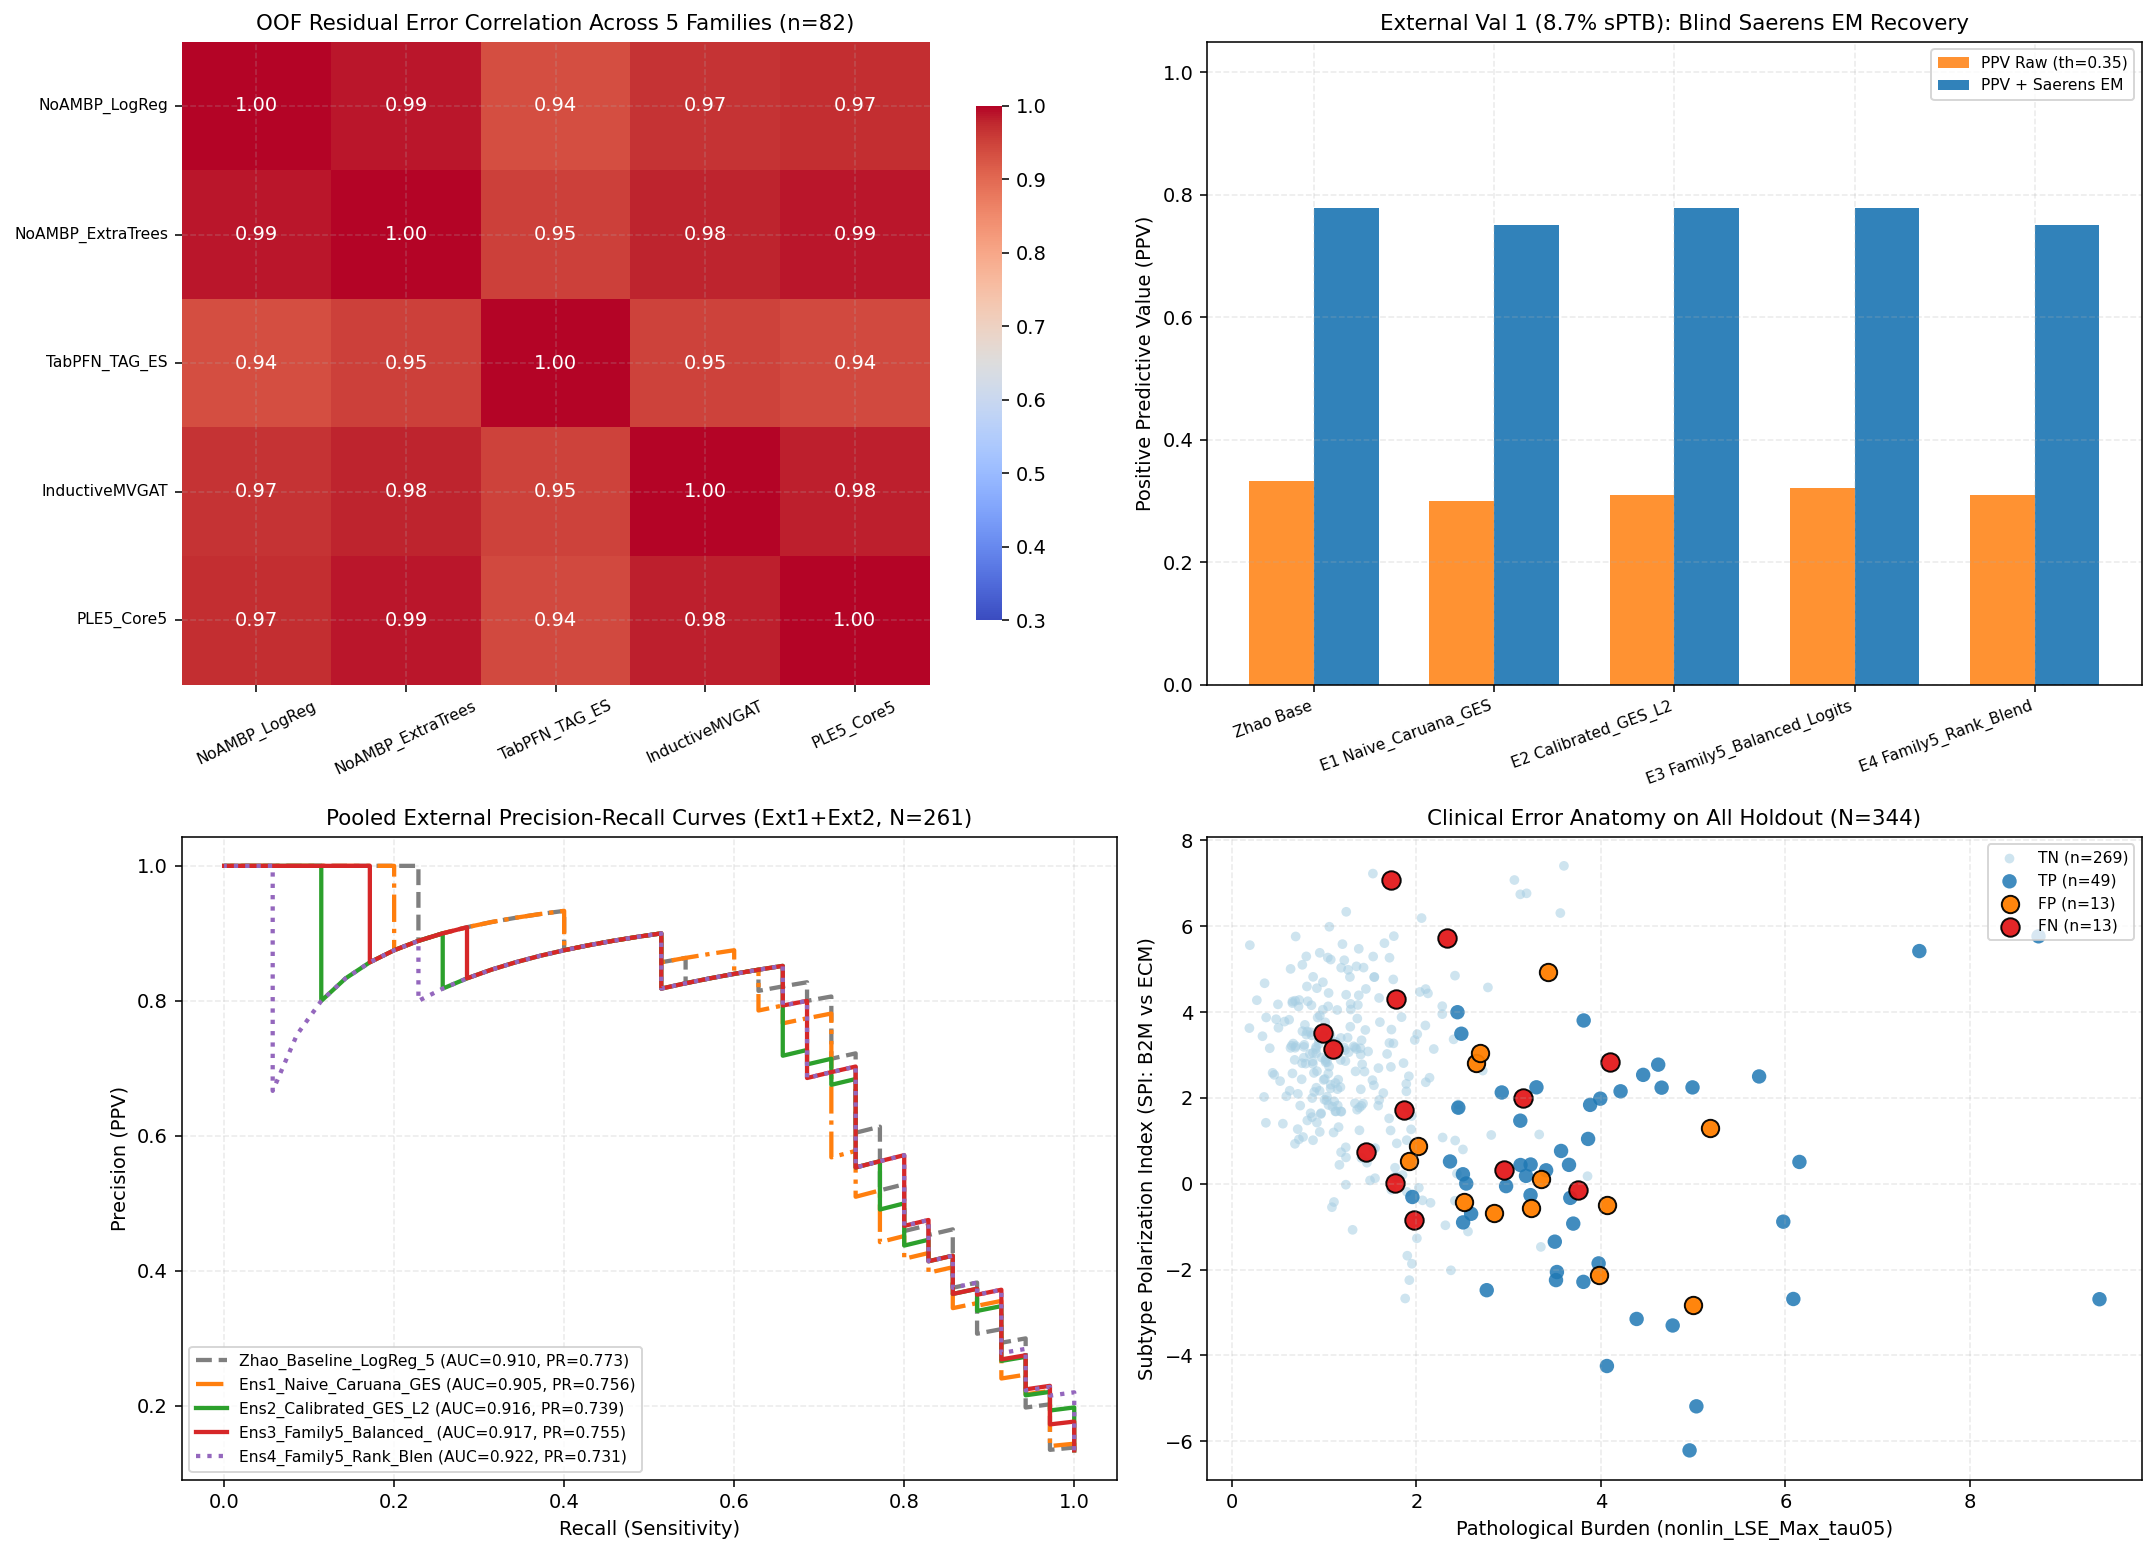


=== СВОДНЫЙ МОСТ С ТРЕКОМ C (ПОЛНОПРОТЕОМНЫЙ АТЛАС Г. ЧУНЦИНА N=35 x 2699) ===
                             Exp     Macro_AUROC        Macro_F1         Bal_Acc  LogLoss  Risk_Pearson_r  Risk_Spearman_rho  Risk_RMSE
       C1a_BINN_Full_BaseTeacher 0.8889 ± 0.0563 0.7360 ± 0.0872 0.7492 ± 0.0873   0.6563 0.6566 ± 0.0417             0.6688     1.4404
  C1b_PNET_SkipHeads_BaseTeacher 0.9321 ± 0.0259 0.7763 ± 0.0687 0.7818 ± 0.0636   0.4415 0.7466 ± 0.0429             0.7610     1.2523
         C2_PNET_Abl_GaussianLOD 0.9340 ± 0.0273 0.7545 ± 0.0773 0.7632 ± 0.0714   0.4252 0.7657 ± 0.0384             0.7753     1.2072
C2b_PNET_AntiTautology_No4Bridge 0.9327 ± 0.0251 0.7777 ± 0.0682 0.7838 ± 0.0622   0.4407 0.7463 ± 0.0430             0.7601     1.2528

[LIONESS U-профиль на OOF P-NET]:
OOF_Predicted_Subtype  N  Mean_LIONESS_k  Mean_JSD_FTB  Mean_ZnCu_Score  Mean_Complement_Score
      Pred_0_FTB_like 18           99.65        0.0204          -0.6676                -0.5806
  Pred_1_sPTB1_

In [11]:
ens4_key = "Ens4_Family5_Prob_Blend" if "Ens4_Family5_Prob_Blend" in calibrated_probs_store else "Ens4_Family5_Rank_Blend"

_, p_base_raw, p_base_em = calibrated_probs_store["Zhao_Baseline_LogReg_5Markers"]
_, p_ens3_raw, p_ens3_em = calibrated_probs_store["Ens3_Family5_Balanced_Logits"]
_, p_ens2_raw, p_ens2_em = calibrated_probs_store["Ens2_Calibrated_GES_L2"]

pred_base = (p_base_em >= 0.35).astype(int)
pred_ens3 = (p_ens3_em >= 0.35).astype(int)

df_err_all = pd.DataFrame({
    "Sample_ID": holdout_ids,
    "Dataset": ds_holdout,
    "Target": y_holdout,
    "p_Base_EM": np.round(p_base_em, 4),
    "p_Ens3_EM": np.round(p_ens3_em, 4),
    "pred_Base": pred_base,
    "pred_Ens3": pred_ens3,
    "AMBP": np.round(cohort_a.loc[holdout_ids, "AMBP"].values, 3),
    "FN1": np.round(cohort_a.loc[holdout_ids, "FN1"].values, 3),
    "LUM": np.round(cohort_a.loc[holdout_ids, "LUM"].values, 3),
    "TIMP1": np.round(cohort_a.loc[holdout_ids, "TIMP1"].values, 3),
    "B2M": np.round(cohort_a.loc[holdout_ids, "B2M"].values, 3),
    "SPI_Polarization": np.round(cohort_a.loc[holdout_ids, "idx_Subtype_Polarization_SPI"].values, 3),
    "Mahalanobis_Dist": np.round(cohort_a.loc[holdout_ids, "nonlin_Mahalanobis_Dist"].values, 3),
    "LSE_Max_tau05": np.round(cohort_a.loc[holdout_ids, "nonlin_LSE_Max_tau05"].values, 3),
    "ELISA_Weight_Wi": np.round(cohort_a.loc[holdout_ids, "sample_reliability_weight"].values, 3),
})

def classify_outcome(row):
    if row["Target"] == 1 and row["pred_Ens3"] == 1:
        return "TP"
    if row["Target"] == 0 and row["pred_Ens3"] == 0:
        return "TN"
    if row["Target"] == 0 and row["pred_Ens3"] == 1:
        return "FP"
    return "FN"

df_err_all["Outcome_Ens3"] = df_err_all.apply(classify_outcome, axis=1)

rescued_mask = (df_err_all["pred_Base"] != df_err_all["Target"]) & (df_err_all["pred_Ens3"] == df_err_all["Target"])
regressed_mask = (df_err_all["pred_Base"] == df_err_all["Target"]) & (df_err_all["pred_Ens3"] != df_err_all["Target"])
print(f"\n=== EXP D3: КЛИНИЧЕСКИЙ ERROR ANALYSIS (ALL HOLDOUT N=344) ===")
print(f"Ошибок Baseline (EM): {(df_err_all['pred_Base'] != df_err_all['Target']).sum()} / 344")
print(f"Ошибок Ens3_Family5 (EM): {(df_err_all['pred_Ens3'] != df_err_all['Target']).sum()} / 344")
print(f"Спасено ансамблем (ошибка Base -> верно Ens3): {rescued_mask.sum()} | Ухудшено: {regressed_mask.sum()}")

print("\n[Профили групп TP / TN / FP / FN ансамбля Ens3_Family5]:")
print(df_err_all.groupby("Outcome_Ens3")[["LUM", "B2M", "SPI_Polarization", "LSE_Max_tau05", "Mahalanobis_Dist", "ELISA_Weight_Wi"]].agg(["count", "mean"]).round(3).to_string())

print("\n[Примеры ошибок FP/FN (топ-12 по уверенности) и спасённых пациенток]:")
err_cases = df_err_all[df_err_all["Outcome_Ens3"].isin(["FP", "FN"])].sort_values("p_Ens3_EM", ascending=False)
print(err_cases[["Sample_ID", "Dataset", "Target", "Outcome_Ens3", "p_Base_EM", "p_Ens3_EM", "LUM", "B2M", "SPI_Polarization", "ELISA_Weight_Wi"]].head(12).to_string(index=False))

if rescued_mask.sum() > 0:
    print("\n[Пациентки, спасённые ансамблем Ens3 против Baseline]:")
    print(df_err_all[rescued_mask][["Sample_ID", "Dataset", "Target", "p_Base_EM", "p_Ens3_EM", "LUM", "B2M", "SPI_Polarization"]].to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(15.5, 11.2))

ax = axes[0, 0]
corr_mat = err_df.corr()
short_labels = [c.replace("TrackA_Best_", "").replace("P5_MS_Top4_", "").replace("TabM_mini_", "") for c in corr_mat.columns]
sns.heatmap(corr_mat.values, annot=True, fmt=".2f", cmap="coolwarm", vmin=0.3, vmax=1.0,
            xticklabels=short_labels, yticklabels=short_labels, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("OOF Residual Error Correlation Across 5 Families (n=82)")
ax.tick_params(axis="x", rotation=25, labelsize=8)
ax.tick_params(axis="y", rotation=0, labelsize=8)

ax = axes[0, 1]
ext1_sub = df_d2[(df_d2["Cohort"] == "External_Val1 (n=127, 8.7%)") & (df_d2["Model"].isin([
    "Zhao_Baseline_LogReg_5Markers",
    "Ens1_Naive_Caruana_GES",
    "Ens2_Calibrated_GES_L2",
    "Ens3_Family5_Balanced_Logits",
    ens4_key,
]))]
x_i = np.arange(len(ext1_sub))
w_b = 0.36
ax.bar(x_i - w_b / 2, ext1_sub["PPV_Raw"], width=w_b, color="#ff7f0e", alpha=0.85, label="PPV Raw (th=0.35)")
ax.bar(x_i + w_b / 2, ext1_sub["PPV_EM"], width=w_b, color="#1f77b4", alpha=0.92, label="PPV + Saerens EM")
ax.set_xticks(x_i)
ax.set_xticklabels([m.replace("Zhao_Baseline_LogReg_5Markers", "Zhao Base").replace("Ens1_", "E1 ").replace("Ens2_", "E2 ").replace("Ens3_", "E3 ").replace("Ens4_", "E4 ") for m in ext1_sub["Model"]], rotation=20, ha="right", fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Positive Predictive Value (PPV)")
ax.set_title("External Val 1 (8.7% sPTB): Blind Saerens EM Recovery")
ax.legend(fontsize=8)

ax = axes[1, 0]
y_ep = y_holdout[m_ext_pool]
plot_curves = [
    ("Zhao_Baseline_LogReg_5Markers", "#7f7f7f", "--"),
    ("Ens1_Naive_Caruana_GES", "#ff7f0e", "-."),
    ("Ens2_Calibrated_GES_L2", "#2ca02c", "-"),
    ("Ens3_Family5_Balanced_Logits", "#d62728", "-"),
    (ens4_key, "#9467bd", ":"),
]
for m_lbl, col_v, ls_v in plot_curves:
    p_v = calibrated_probs_store[m_lbl][1][m_ext_pool]
    prec, rec, _ = precision_recall_curve(y_ep, p_v)
    ap_v = average_precision_score(y_ep, p_v)
    auc_v = roc_auc_score(y_ep, p_v)
    ax.plot(rec, prec, lw=2.2, color=col_v, ls=ls_v, label=f"{m_lbl[:22]} (AUC={auc_v:.3f}, PR={ap_v:.3f})")
ax.set_xlabel("Recall (Sensitivity)")
ax.set_ylabel("Precision (PPV)")
ax.set_title("Pooled External Precision-Recall Curves (Ext1+Ext2, N=261)")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1, 1]
palette_err = {"TN": "#a6cee3", "TP": "#1f78b4", "FP": "#ff7f00", "FN": "#e31a1c"}
for grp, sz, al in [("TN", 25, 0.55), ("TP", 55, 0.85), ("FP", 80, 0.95), ("FN", 90, 0.95)]:
    sub_g = df_err_all[df_err_all["Outcome_Ens3"] == grp]
    ax.scatter(sub_g["LSE_Max_tau05"], sub_g["SPI_Polarization"], s=sz, c=palette_err[grp],
               edgecolor="black" if grp in ("FP", "FN") else "none", alpha=al, label=f"{grp} (n={len(sub_g)})")
ax.set_xlabel("Pathological Burden (nonlin_LSE_Max_tau05)")
ax.set_ylabel("Subtype Polarization Index (SPI: B2M vs ECM)")
ax.set_title("Clinical Error Anatomy on All Holdout (N=344)")
ax.legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "TrackD_Final_Synthesis_Report.png", dpi=300)
plt.show()

c_abl_path = TRACK_C_DIR / "exp_c1_c2_binn_ablations.csv"
c_lion_path = TRACK_C_DIR / "exp_c3_lioness_uprofile.csv"
if c_abl_path.exists() and c_lion_path.exists():
    print("\n=== СВОДНЫЙ МОСТ С ТРЕКОМ C (ПОЛНОПРОТЕОМНЫЙ АТЛАС Г. ЧУНЦИНА N=35 x 2699) ===")
    c_abl = pd.read_csv(c_abl_path)
    print(c_abl[c_abl["Exp"].isin([
        "C1a_BINN_Full_BaseTeacher",
        "C1b_PNET_SkipHeads_BaseTeacher",
        "C2_PNET_Abl_GaussianLOD",
        "C2b_PNET_AntiTautology_No4Bridge",
    ])].to_string(index=False))
    print("\n[LIONESS U-профиль на OOF P-NET]:")
    print(pd.read_csv(c_lion_path).to_string(index=False))

df_master.to_csv(TRACK_D_DIR / "track_d_master_leaderboard.csv", index=False)
df_d2.to_csv(TRACK_D_DIR / "track_d_bootstrap_delong_exam.csv", index=False)
df_err_all.to_csv(TRACK_D_DIR / "track_d_error_analysis.csv", index=False)
with open(TRACK_D_DIR / "track_d_ensemble_weights.json", "w", encoding="utf-8") as f:
    json.dump({
        "Family_Leaders_OOF": family_leaders_oof,
        "Ens1_Naive_Caruana_GES": w_naive_ges,
        "Ens2_Calibrated_GES_L2": w_cal_reg_ges,
        "Ens3_Family5_Balanced_Logits": w_fam5_equal,
    }, f, indent=2)

shutil.make_archive("artifacts", "zip", "artifacts")
print("\n[TRACK D COMPLETE] Финальные таблицы, графики и полный архив `artifacts.zip` готовы!")